# **Phase 2 - Transfer Learning & Data Augmentations**

Please follow the notebook in order. Make sure to add code where indicated by `''' TODO '''` or `# YOUR CODE HERE`. Please answer all questions indicated with '❓', and answer where it says 'ANSWER HERE'.

Ensure your notebook is easy to follow. All written report answers should be provided in the notebook itself.

In [3]:
%pip install torch torchvision


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import time
import os
import copy

import matplotlib.pyplot as plt
import numpy as np
import torchvision

## **Overview**
1. CIFAR10 Dataset
2. Data Augmentations
3. Transfer learning with ResNet Architecture
4. Training ResNet Architecture

# **1. CIFAR10 Dataset**

This is an RGB dataset with 10 classes:

*plane, car, bird, cat, deer, dog, frog, horse, ship, truck*


## **1.1 Download and Load CIFAR10**

You can find CIFAR10 in ```torchvision.datasets.CIFAR10()``` or see [here](https://pytorch.org/vision/0.15/generated/torchvision.datasets.CIFAR10.html#torchvision.datasets.CIFAR10). Please Download the dataset and use Dataloaders to load it. This is identical to loading MNIST.

In [6]:
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 64

# Load CIFAR-10 training set
train_set = datasets.CIFAR10(root = './data', train = True,
                             transform = transform, download = True)

train_loader = torch.utils.data.DataLoader(dataset = train_set,
                                           batch_size = batch_size,
                                           shuffle = True)

# Load CIFAR-10 test set
testset = datasets.CIFAR10(root = './data', train = False,
                           transform = transform, download = True)

test_loader = torch.utils.data.DataLoader(dataset = testset,
                                          batch_size = batch_size,
                                          shuffle = False)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')


100.0%


## **1.2 Display CIFAR10 Images**

Similar to Phase 1, please complete `show_imgs()` function to display 10 images. However, this time we want to display exactly one image per class. There are 10 classes total. Show a random image per class with their label.

In [15]:
import numpy as np
import matplotlib.pyplot as plt

def show_imgs(dataloader, classes):
    # Grab one random image per class (loader is shuffled, so it's random each time)
    found = {}
    for images, labels in dataloader:
        for img, label in zip(images, labels):
            label = label.item()
            if label not in found:
                found[label] = img
        if len(found) == len(classes):
            break

    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    for i, ax in enumerate(axes.flat):
        img = found[i] * 0.5 + 0.5              # undo Normalize((0.5,...), (0.5,...))
        img = img.numpy().transpose((1, 2, 0))  # (C, H, W) -> (H, W, C)
        ax.imshow(np.clip(img, 0, 1))
        ax.set_title(classes[i])
        ax.axis('off')
    plt.tight_layout()
    plt.show()


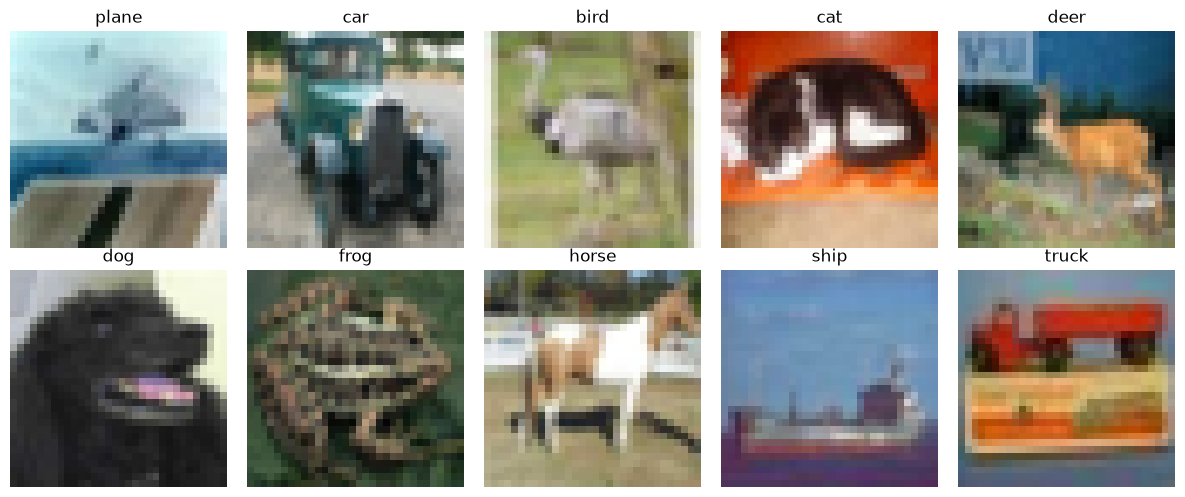

In [16]:
show_imgs(train_loader, classes)

# **2. Data Augmentations**

## **2.1 Use Built-in Augmentations**

Use augmentations from the `torchvision.transforms` library [
link](https://pytorch.org/vision/0.9/transforms.html). Apply the following. For the parameters, please test and choose suitable ones.


*   Horizontal Flip
*   Random Crop
*   Color Jitter
*   Random Resized Crop

Try each of these individually and display the augmented images using your `show_imgs()` function.

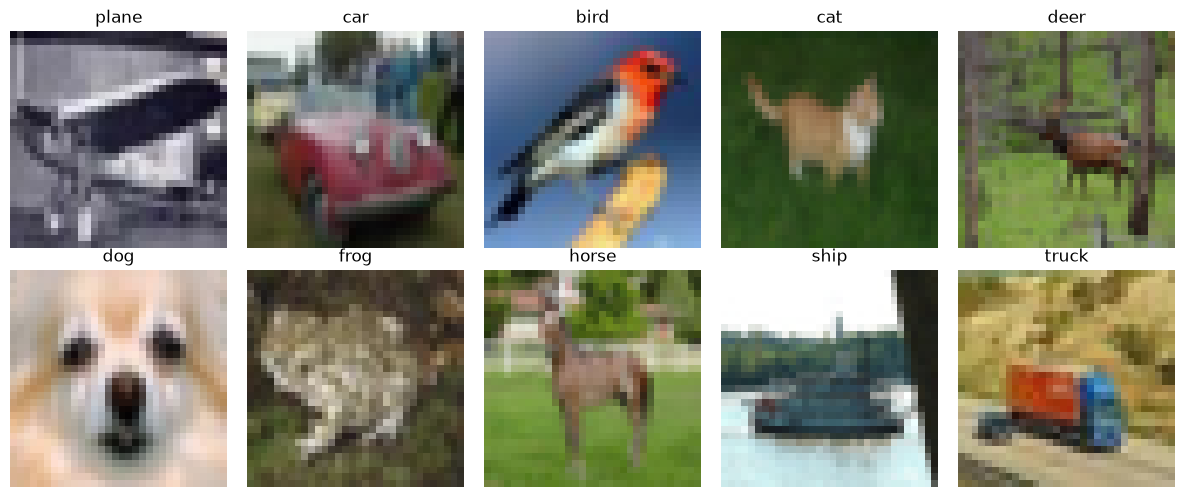

In [17]:
# Horizontal Flip
aug_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Define a dataset & loader with augmentations
train_aug_set = datasets.CIFAR10(root = './data', train = True,
                                 transform = aug_transform, download = True)

train_aug_loader = torch.utils.data.DataLoader(dataset = train_aug_set,
                                               batch_size = batch_size,
                                               shuffle = True)

# Display images with augmentations
show_imgs(train_aug_loader, classes)


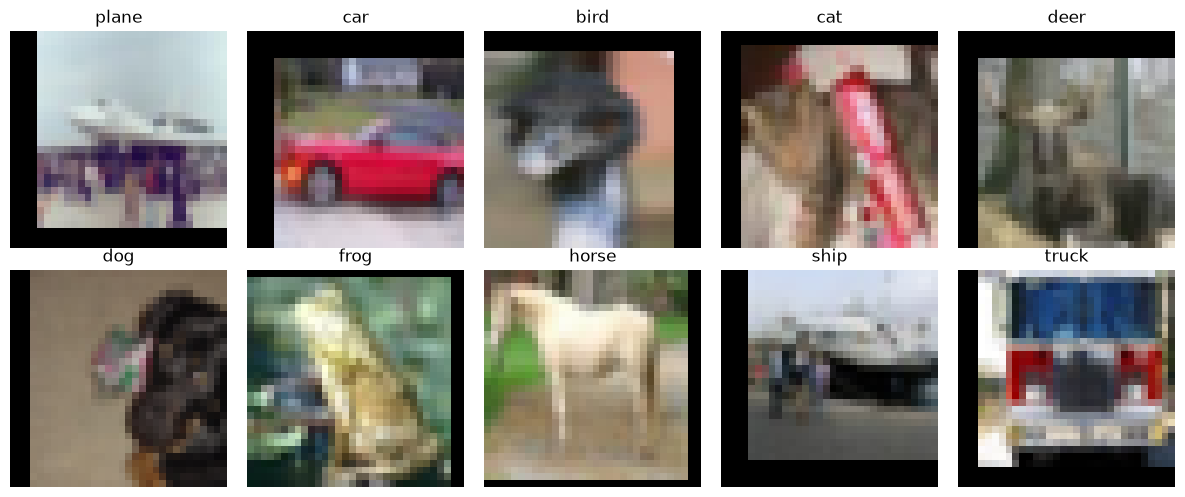

In [18]:
# Random Crop
aug_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Define a dataset & loader with augmentations
train_aug_set = datasets.CIFAR10(root = './data', train = True,
                                 transform = aug_transform, download = True)

train_aug_loader = torch.utils.data.DataLoader(dataset = train_aug_set,
                                               batch_size = batch_size,
                                               shuffle = True)

# Display images with augmentations
show_imgs(train_aug_loader, classes)


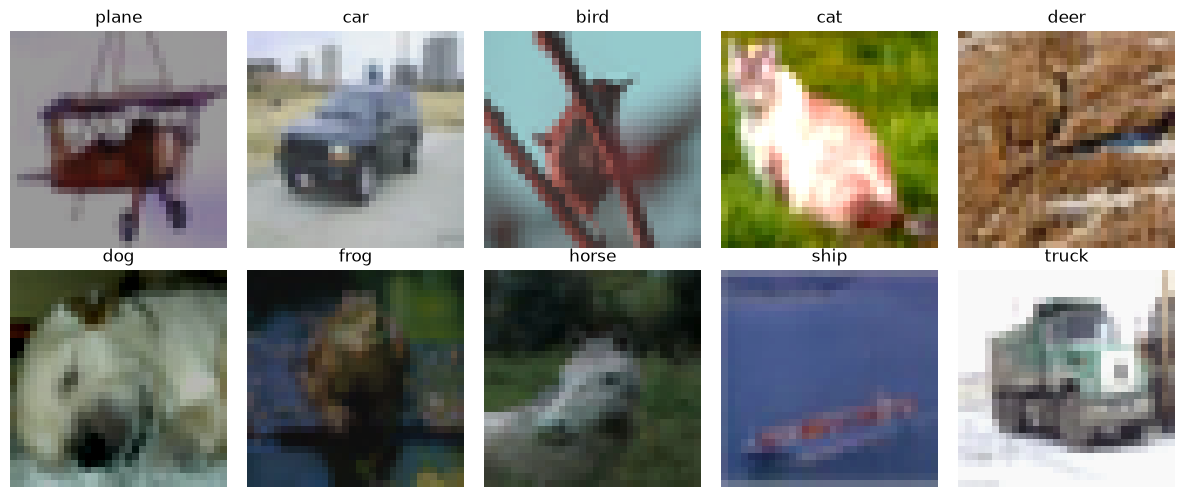

In [19]:
# Color Jitter
aug_transform = transforms.Compose([
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Define a dataset & loader with augmentations
train_aug_set = datasets.CIFAR10(root = './data', train = True,
                                 transform = aug_transform, download = True)

train_aug_loader = torch.utils.data.DataLoader(dataset = train_aug_set,
                                               batch_size = batch_size,
                                               shuffle = True)

# Display images with augmentations
show_imgs(train_aug_loader, classes)


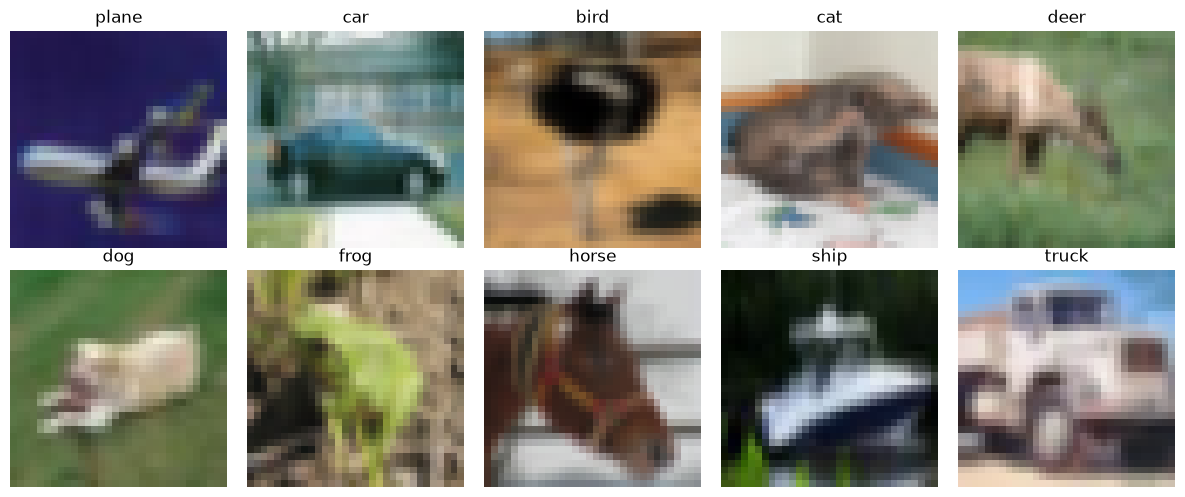

In [20]:
# Random Resized Crop
aug_transform = transforms.Compose([
    transforms.RandomResizedCrop(32, scale=(0.6, 1.0), ratio=(0.75, 1.33)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Define a dataset & loader with augmentations
train_aug_set = datasets.CIFAR10(root = './data', train = True,
                                 transform = aug_transform, download = True)

train_aug_loader = torch.utils.data.DataLoader(dataset = train_aug_set,
                                               batch_size = batch_size,
                                               shuffle = True)

# Display images with augmentations
show_imgs(train_aug_loader, classes)


### ❓ **Q 2.1.1 Please explain what Data augmentations are and their use. What is the purpose of making them random?**

Data augmentations are transformations applied to training images, like flips, crops, and color changes, that create new variations of the existing data so the model sees a larger, more diverse training set and overfits less. Making them random means the model sees a different version of each image every epoch, so it can't memorize exact pixels and instead learns features.

___
### ❓ **Q 2.1.2 Please explain all of the augmentations you are using. What is the value of each of them?**

Horizontal Flip (p=0.5) mirrors half the images so the model recognizes objects facing either direction, and Random Crop (32, padding=4) shifts images by up to 4 pixels so the model doesn't depend on where the object sits in the frame. Color Jitter (brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1) changes the colors by up to ±40% so the model handles different lighting, and Random Resized Crop (scale=(0.6, 1.0)) zooms into 60–100% of the image so the model learns objects at different sizes without cropping them out of a 32×32 image.

## **2.2 Custom Augmentations**

Create a custom data augmentation function. Please do rotation, randomly between -30 and 30 degrees. You must code this yourself, do not use the torchvision function.

[This tutorial ](https://pytorch.org/tutorials/beginner/data_loading_tutorial.html) may be useful. You can use `PIL` image manupilation libraries, but NOT torchvision ones. Do not import any other libraries. You should only need:



```
from PIL import Image
import random
```





Apply this custom augmentation to the images and display the results using `show_imgs()`.

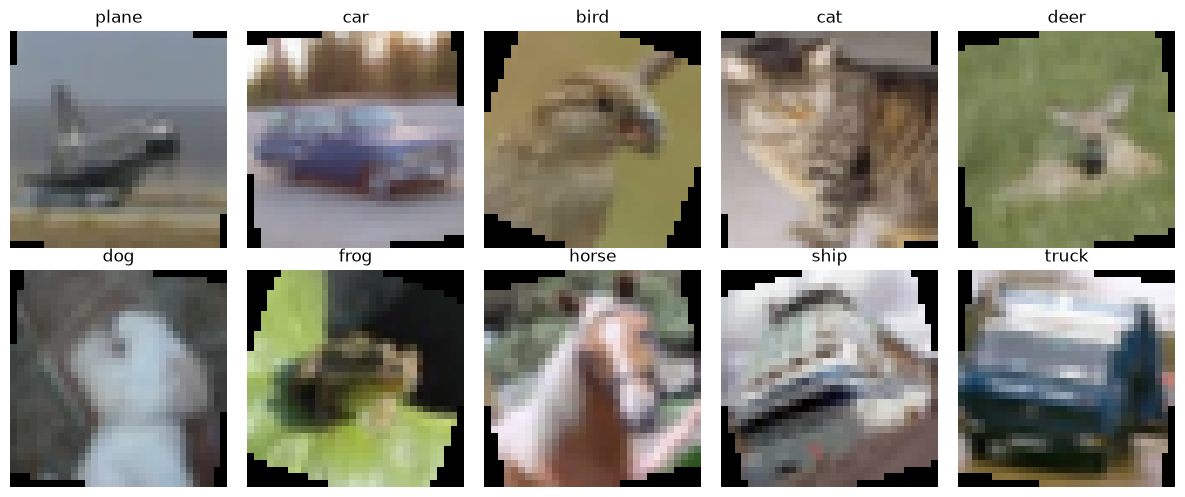

In [21]:
from PIL import Image
import random

class RandomRotate:
    def __init__(self, min_angle=-30, max_angle=30):
        self.min_angle = min_angle
        self.max_angle = max_angle

    def __call__(self, img):
        # img is a PIL Image (CIFAR10 returns PIL images before ToTensor)
        angle = random.uniform(self.min_angle, self.max_angle)
        return img.rotate(angle, resample=Image.BILINEAR)

# Apply Transform
rotate_transform = transforms.Compose([
    RandomRotate(-30, 30),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_set_rotate = datasets.CIFAR10(root = './data', train = True,
                                    transform = rotate_transform, download = True)

train_loader_rotate = torch.utils.data.DataLoader(dataset = train_set_rotate,
                                                  batch_size = batch_size,
                                                  shuffle = True)

# Display images with the custom augmentation
show_imgs(train_loader_rotate, classes)


### ❓ **Q 2.2.1 Explain how you would determine what is a good lower and upper limit for rotation? We use -30 to 30, why does that make sense?**

A good rotation range covers how much objects realistically tilt in real photos, and you check it by viewing the augmented images and comparing validation accuracy across different ranges, stopping before the images stop looking natural or accuracy drops. ±30° makes sense because CIFAR-10 objects like cars, animals, and ships are almost always upright, so small tilts mimic real camera angles, while larger rotations would create upside-down images the model will never see and leave big black corners on the 32×32 images.

____

# **3. Transfer Learning**
Load ResNet18 model from ```torchvision.models.resnet18()```, make sure to load pretrained model with [weights](https://pytorch.org/vision/stable/models.html).
You will need to modify the final layer. ResNet outputs 100 labels - please change to the correct output dimension.

## **3.1 ResNet18**

In [22]:
from torchvision.models import resnet18, ResNet18_Weights

# Instantiate Pretrained ResNet18
resnet18 = models.resnet18(weights=ResNet18_Weights.DEFAULT)

# Modify final layer
resnet18.fc = nn.Linear(resnet18.fc.in_features, len(classes))   # 512 -> 10

# Load onto GPU
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
resnet18 = resnet18.to(device)

# View Model to validate
print(resnet18)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\cheem/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

## **3.2 Train ResNet on CIFAR10**

### **3.2.1 Train and Test Functions**
You can refer to Phase_1.ipynb to complete these functions. In ```train()```, rather than saving the accuracy and loss per iteration, you will need to save the loss and accuracy ***per epoch***. Plot loss and accuracy plots for both train and validation sets.

In [24]:
# Train Function
def train(model, loss_fn, optimizer, train_loader, val_loader, num_epochs, device):
    model.to(device)
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(num_epochs):
        # ---------- Train ----------
        start = time.time()
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = 100 * correct / total
        train_time = time.time() - start

        # ---------- Validation ----------
        start = time.time()
        model.eval()
        running_loss, correct, total = 0.0, 0, 0

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)

                outputs = model(images)
                loss = loss_fn(outputs, labels)

                running_loss += loss.item() * labels.size(0)
                _, predicted = torch.max(outputs, 1)
                correct += (predicted == labels).sum().item()
                total += labels.size(0)

        val_loss = running_loss / total
        val_acc = 100 * correct / total
        val_time = time.time() - start

        # ---------- Save + print (per epoch) ----------
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f'Epoch [{epoch+1}/{num_epochs}]  '
              f'Train Loss: {train_loss:.4f}  Train Acc: {train_acc:.2f}%  ({train_time:.1f}s)  |  '
              f'Val Loss: {val_loss:.4f}  Val Acc: {val_acc:.2f}%  ({val_time:.1f}s)')

    return history

# Test Function
def test_accuracy(model, test_loader, device):
    model.to(device)
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    acc = 100 * correct / total
    print(f'Test Accuracy: {acc:.2f} %')
    return acc

# Plot Learning Curves
def plot_learning_curve(history, title=''):
    epochs = range(1, len(history['train_loss']) + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    # Loss
    ax1.plot(epochs, history['train_loss'], marker='o', label='Train')
    ax1.plot(epochs, history['val_loss'], marker='o', label='Validation')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.set_title('Loss')
    ax1.legend()
    ax1.grid(True)

    # Accuracy
    ax2.plot(epochs, history['train_acc'], marker='o', label='Train')
    ax2.plot(epochs, history['val_acc'], marker='o', label='Validation')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy (%)')
    ax2.set_title('Accuracy')
    ax2.legend()
    ax2.grid(True)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


### **3.2.2 Train and Plot Learning Curvesrn**

Retrain the ResNet18 on CIFAR10 Dataset. You can chose the optimizer and loss function. Train first with then without data augmentation to compare. When using data augmentations, you can choose which augmentations to use!

In [27]:
## TRAINING WITHOUT AUGMENTATIONS

# Define Parameters
num_epochs = 10
lr = 1e-4

# Define Loss func and Optimizer
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(resnet18.parameters(), lr=lr)

# Train Model
history_no_aug = train(resnet18, loss_function, optimizer, train_loader, test_loader, num_epochs, device)

# Plot Learning Curves
plot_learning_curve(history_no_aug, 'ResNet18 - No Augmentations')

# Evaluate on Test Set
test_accuracy(resnet18, test_loader, device)


KeyboardInterrupt: 

In [ ]:
## TRAINING WITH AUGMENTATIONS

# Define Parameters
num_epochs = 10
lr = 1e-4

# Augmentations used for training (test set stays un-augmented)
train_aug_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_aug_set = datasets.CIFAR10(root = './data', train = True,
                                 transform = train_aug_transform, download = True)

train_aug_loader = torch.utils.data.DataLoader(dataset = train_aug_set,
                                               batch_size = batch_size,
                                               shuffle = True)

# Fresh pretrained ResNet18 so the comparison is fair
resnet18_aug = models.resnet18(weights=ResNet18_Weights.DEFAULT)
resnet18_aug.fc = nn.Linear(resnet18_aug.fc.in_features, len(classes))
resnet18_aug = resnet18_aug.to(device)

# Define Loss func and Optimizer
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(resnet18_aug.parameters(), lr=lr)

# Train Model
history_aug = train(resnet18_aug, loss_function, optimizer, train_aug_loader, test_loader, num_epochs, device)

# Plot Learning Curves
plot_learning_curve(history_aug, 'ResNet18 - With Augmentations')

# Evaluate on Test Set
test_accuracy(resnet18_aug, test_loader, device)


### **3.2.3 Confusion Matrix**

Write code to plot a confusion matrix after training the above ResNet18. Please make sure the axis have class names (defined in Section 1)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(model, data_loader, classes, device, title='Confusion Matrix'):
    # Collect predictions and true labels
    model.to(device)
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.numpy())

    cm = confusion_matrix(all_labels, all_preds)

    # Plot
    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(cm, cmap='Blues')
    fig.colorbar(im, ax=ax)

    ax.set_xticks(np.arange(len(classes)))
    ax.set_yticks(np.arange(len(classes)))
    ax.set_xticklabels(classes, rotation=45, ha='right')
    ax.set_yticklabels(classes)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    ax.set_title(title)

    # Write counts in each cell
    thresh = cm.max() / 2
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, cm[i, j], ha='center', va='center',
                    color='white' if cm[i, j] > thresh else 'black')

    plt.tight_layout()
    plt.show()

plot_confusion_matrix(resnet18_aug, test_loader, classes, device, 'ResNet18 (With Augmentations) - Test Set')


## **3.2.4 Freeze Network**

Initialize a new ResNet18, Freeze all the non-linear or non-fc weights. Hence, we will only be training the fc layers.

Freezing implies setting `requires_grad = False` for selected parameters


In [ ]:
# Instantiate Pretrained ResNet18
resnet18_frz = models.resnet18(weights=ResNet18_Weights.DEFAULT)

# Freeze all layers (except classifier/linear layers)
for param in resnet18_frz.parameters():
    param.requires_grad = False

# New fc layer (trainable by default) for 10 classes
resnet18_frz.fc = nn.Linear(resnet18_frz.fc.in_features, len(classes))
resnet18_frz = resnet18_frz.to(device)

# Check which params are trainable
trainable = sum(p.numel() for p in resnet18_frz.parameters() if p.requires_grad)
total = sum(p.numel() for p in resnet18_frz.parameters())
print(f'Trainable params: {trainable} / {total}')

# View Model to validate
print(resnet18_frz)


### **3.2.5 Train frozen ResNet18**

Retrain the frozen ResNet18 now with the same setup as the previous ResNet18 (same batch size, optimizer, learning rate, etc.) for direct comparison. The results may not be as good that is expected.

In [ ]:
## TRAINING WITHOUT AUGMENTATIONS

# Define Parameters
num_epochs = 10
lr = 1e-4

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, resnet18_frz.parameters()), lr=lr)

# Train the model
history_frz = train(resnet18_frz, loss_function, optimizer, train_loader, test_loader, num_epochs, device)

# Plot the learning curve
plot_learning_curve(history_frz, 'ResNet18 Frozen (fc only) - No Augmentations')

# Evaluate on Test Set
test_accuracy(resnet18_frz, test_loader, device)


### ❓ **Q 3.2.6 What was the difference when training with and without data augmentations?**

ANSWER HERE

___
### ❓ **Q 3.2.7 What is transfer learning and why would it be useful?**

ANSWER HERE

___
### ❓ **Q 3.2.8 What was the difference between freezing layers and retraining all? Explain in terms of classification metrics and why you saw such metrics and confusuon matrix. Is what you say as expected?**

ANSWER HERE

___
### ❓ **Q 3.2.9 For a pretrained model like ResNet, in what general scenarios would you (1) freeze your pretrained weights adn retrain last layer, (2) retrain entire architecture, and (3) Freeze all convolution layer weights and retrain all FC layers? Explain with example scenarios if possible.**

ANSWER HERE

___


### **3.2.10 Train frozen ResNet18 for better performance**

You may have noticed only training just the fc layer did not yield good performance. Now, you must try to investigate trying to freeze as much of the original model as possible for best results.


*   Keep fc layer unfrozen, and unfreeze the last block (in layer4 of resnet18)
*   You pick which layers to unfreeze!

Investigate the maximize the layers to unfreeze to yield best balance between performance to training time.

In [ ]:
# Instantiate Pretrained ResNet18
resnet18_frz = models.resnet18(weights=ResNet18_Weights.DEFAULT)

# Freeze everything first
for param in resnet18_frz.parameters():
    param.requires_grad = False

# Unfreeze the last block (in layer4 of resnet18)
for param in resnet18_frz.layer4[-1].parameters():
    param.requires_grad = True

# New fc layer (trainable by default)
resnet18_frz.fc = nn.Linear(resnet18_frz.fc.in_features, len(classes))
resnet18_frz = resnet18_frz.to(device)

trainable = sum(p.numel() for p in resnet18_frz.parameters() if p.requires_grad)
total = sum(p.numel() for p in resnet18_frz.parameters())
print(f'Trainable params: {trainable} / {total}')

## TRAINING WITHOUT AUGMENTATIONS
# Define Parameters
num_epochs = 10
lr = 1e-4

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, resnet18_frz.parameters()), lr=lr)

# Train the model
history_frz_l4 = train(resnet18_frz, loss_function, optimizer, train_loader, test_loader, num_epochs, device)

# Plot the learning curve
plot_learning_curve(history_frz_l4, 'ResNet18 - Last layer4 Block + fc Unfrozen')

# Evaluate on Test Set
test_accuracy(resnet18_frz, test_loader, device)


In [ ]:
# Instantiate Pretrained ResNet18
resnet18_frz = models.resnet18(weights=ResNet18_Weights.DEFAULT)

# Freeze whichever layers you choose for best performance
# Freeze early layers (conv1, bn1, layer1, layer2), train layer3 + layer4 + fc
for param in resnet18_frz.parameters():
    param.requires_grad = False

for layer in [resnet18_frz.layer3, resnet18_frz.layer4]:
    for param in layer.parameters():
        param.requires_grad = True

# New fc layer (trainable by default)
resnet18_frz.fc = nn.Linear(resnet18_frz.fc.in_features, len(classes))
resnet18_frz = resnet18_frz.to(device)

trainable = sum(p.numel() for p in resnet18_frz.parameters() if p.requires_grad)
total = sum(p.numel() for p in resnet18_frz.parameters())
print(f'Trainable params: {trainable} / {total}')

## TRAINING WITHOUT AUGMENTATIONS
# Define Parameters
num_epochs = 10
lr = 1e-4

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, resnet18_frz.parameters()), lr=lr)

# Train the model
history_frz_best = train(resnet18_frz, loss_function, optimizer, train_loader, test_loader, num_epochs, device)

# Plot the learning curve
plot_learning_curve(history_frz_best, 'ResNet18 - layer3 + layer4 + fc Unfrozen')

# Evaluate on Test Set
test_accuracy(resnet18_frz, test_loader, device)



### ❓ **Q 3.2.11 Which layers did you freeze to yield the best performance vs training time balance? Can you give any intuition as to why this worked well? Compare it with unfreezing only the fc layer and explain why it performs better.**

ANSWER HERE

___
___
# End of Phase 2 😊🥳